# Synapse mechanisms (Figure 7)

Isolated-synapse and reduced circuit experiments characterising the synaptic
mechanisms used in the network model. Figures are written to
`results/network_sim/synapses/`.

| Manuscript figure | Section |
| --- | --- |
| Fig. 7 a–e | NMDA (Gao) vs Exp2Syn |
| Fig. 7 g, h | NMDA spikes in the basal dendrites (network) |
| Fig. 7 i–k | NMDA vs GABA_A and E/I interplay |
| Fig. 7 l–n | GABA_B (old vs new) |


In [1]:
# Author: Katharina Duecker <katharina.duecker@gmail.com>
# last checked: 18-Oct-2026

In [2]:
# settings
import gc
import math

import neuron
from neuron import h
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

from hnn_core import duecker_ET_model, simulate_dipole, MPIBackend

# hnn-tuning settings
from hnn_tuning import HNN_CORE_MOD, results_dir
from hnn_tuning.l5_plot_utils import get_l5pyr
from hnn_tuning.plot_utils import add_scalebar

neuron.load_mechanisms(str(HNN_CORE_MOD))
h.load_file("stdrun.hoc")

figpth = results_dir('network_sim', 'synapses')
import os
os.makedirs(figpth, exist_ok=True)

plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['pdf.fonttype'] = 42

# colours reused across panels
COL_PRE = '#a52051'      # presynaptic soma
COL_POST_SOMA = 'k'      # postsynaptic soma
COL_POST_DEND = '#436aa1'  # postsynaptic dendrite

# Fig. 7 g, h only (network experiment): number of neighbouring L5 cells that are
# recruited one at a time, their colour code, and the MPI process count.
NUM_NEIGH = 17
COL_NEIGH = plt.get_cmap('viridis')(np.linspace(0, 1, NUM_NEIGH))
N_PROCS = 10


## Helper functions

In [3]:
def drive_soma(name='soma', stim_delay=20, stim_dur=5, stim_amp=0.5):
    """A presynaptic Hodgkin-Huxley soma with a current clamp that makes it spike.

    Returns (soma, stim). The soma's spikes drive a synapse via a NetCon.
    """
    soma = h.Section(name=name)
    soma.L = soma.diam = 12
    soma.Ra = 100
    soma.cm = 1
    soma.insert('hh')
    stim = h.IClamp(soma(0.5))
    stim.delay = stim_delay
    stim.dur = stim_dur
    stim.amp = stim_amp
    return soma, stim


def make_post_basal(name='basal', L=255, diam=8.5):
    """A passive postsynaptic dendrite section (for isolated-synapse experiments)."""
    post = h.Section(name=name)
    post.L = L
    post.diam = diam
    post.Ra = 100
    post.cm = 1
    post.insert('pas')
    return post


def connect(pre_soma, syn, weight, delay=1):
    """NetCon from a presynaptic soma's voltage onto a synapse point process."""
    nc = h.NetCon(pre_soma(0.5)._ref_v, syn, sec=pre_soma)
    nc.weight[0] = weight
    nc.delay = delay
    return nc


def cleanup(*objs):
    """ Delete all point processes and NetCons (called after each experiment)
    """
    for o in objs:
        del o
    gc.collect()
    h('forall delete_section()')
    gc.collect()

## Fig. 7 a–e — NMDA (Gao et al., 2021) vs Exp2Syn

(a) synaptic current of an isolated Exp2Syn vs NMDA_gao2021 synapse; (b, c)
membrane potential when the synapse is placed on an L5 `basal_2` dendrite
(Exp2Syn / NMDA_gao2021); (d) the resulting dendritic Ca²⁺; (e) the NMDA current's
voltage dependence (I–V), measured under voltage clamp.

### Plotting functions (Fig. 7 a–e)

In [4]:
def plot_a(ax):
    # black: Exp2Syn current (left axis); red: NMDA_gao2021 current (right axis)
    ax.plot(a_t, np.abs(a_exp2), color='k')
    ax.set_xlim([0, 500])
    add_scalebar(ax, x_len=200, y_len=1, x_label='200 ms', y_label='1 nA')
    ax2 = ax.twinx()
    ax2.plot(a_t, np.abs(a_gao), color='r', alpha=0.75)
    # twin (right) axis scale bar, offset up so it does not overlap the left bar
    # twin (right) axis: same anchor as the left bar, mirrored horizontally
    add_scalebar(ax2, x_len=200, y_len=0.05, y_label='0.05 nA', flip_x=True,anchor=(1.03, -.03))
    return ax2


def _plot_syn_on_l5(ax, t, v_pre, v_soma, v_dend, dend_label):
    ax.plot(t, v_pre, color=COL_PRE, label='pre soma')
    ax.plot(t, v_soma, color=COL_POST_SOMA, label='post soma')
    ax.plot(t, v_dend, color=COL_POST_DEND, alpha=0.73, label=dend_label)
    ax.set_ylim([-80, 50])
    add_scalebar(ax, x_len=50, y_len=50, x_label='50 ms', y_label='50 mV')


def plot_b(ax):
    _plot_syn_on_l5(ax, b_t, b_vpre, b_vsoma, b_vbasal, 'post basal 2')


def plot_c(ax):
    _plot_syn_on_l5(ax, c_t, c_vpre, c_vsoma, c_vbasal, 'post basal 2')


def plot_d(ax):
    ax.plot(d_t, d_exp2_ca, color='k')            # Exp2Syn
    ax.plot(d_t, d_nmda_ca, color='r', alpha=0.75)  # NMDA_gao2021
    ax.set_ylim([5e-5, 1.25e-4])
    add_scalebar(ax, x_len=50, y_len=3e-5, x_label='50 ms', y_label='3e-5 mM')


def plot_e(ax):
    ax.plot(e_bamps, e_exp2_grad, 'o', color='k')
    ax.plot(e_bamps, e_nmda_grad, 'o', color='r', alpha=0.75)
    ax.set_xlabel('basal membrane pot. (mV)')
    ax.set_ylabel('NMDA current (nA)')
    ax.set_ylim(0, 1)
    ax.set_xlim(-61, 1)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def plot_row_ae(fig=None):
    if fig is None:
        fig, ax = plt.subplots(1, 5, figsize=(16, 2.5), constrained_layout=True)
    else:
        ax = fig.subplots(1, 5)
    plot_a(ax[0])
    plot_b(ax[1])
    plot_c(ax[2])
    plot_d(ax[3])
    plot_e(ax[4])
    return fig, ax

### a — isolated Exp2Syn vs NMDA_gao2021 current

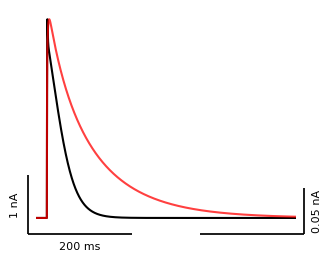

In [5]:
# Exp2Syn
soma_pre, stim = drive_soma()
post = make_post_basal()
syn = h.Exp2Syn(post(0.5))
syn.tau1 = 1
syn.tau2 = 20
syn.e = 0.0
nc = connect(soma_pre, syn, weight=0.1)
t = h.Vector().record(h._ref_t)
exp2curr = h.Vector().record(syn._ref_i)
h.finitialize(-65)
h.continuerun(500)
a_t = t.as_numpy().copy()
a_exp2 = exp2curr.as_numpy().copy()
cleanup(stim, syn, nc, soma_pre, post)

# NMDA_gao2021
soma_pre, stim = drive_soma()
post = make_post_basal()
syn = h.NMDA_gao2021(post(0.5))
nc = connect(soma_pre, syn, weight=0.1)
t = h.Vector().record(h._ref_t)
gaocurr = h.Vector().record(syn._ref_i)
h.finitialize(-65)
h.continuerun(500)
a_gao = gaocurr.as_numpy().copy()
cleanup(stim, syn, nc, soma_pre, post)

fig, ax = plt.subplots(figsize=(3.2, 2.5), constrained_layout=True)
plot_a(ax)
fig.savefig(figpth / 'fig7a_current_exp2syn_vs_nmda.png', dpi=300)
fig.savefig(figpth / 'fig7a_current_exp2syn_vs_nmda.pdf', dpi=300)
plt.show()

### b, d(black), e(black) — Exp2Syn on L5 `basal_2`

Exp2Syn synapse on the L5 `basal_2` dendrite: membrane potential (panel b),
dendritic Ca²⁺ (black trace of panel d), and the NMDA I–V black points (panel
e), the latter measured by clamping the dendrite to a range of voltages.

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod.  Aborting.
Adding synapse(s) ['Exp2Syn'] at ['basal_2']
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod.  Aborting.
Adding synapse(s) ['Exp2Syn'] at ['basal_2']
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod.  Aborting.
Adding synapse(s) ['Exp2Syn'] at ['basal_2']
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod.  Aborting.
Adding synapse(s) ['Exp2Syn'] at ['basal_2']
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod.  Aborting.
Adding synapse(s) ['Exp2Syn'] at ['basal_2']
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod.  Aborting.
Adding synapse(s) ['Exp2Syn'] at ['basal_2']


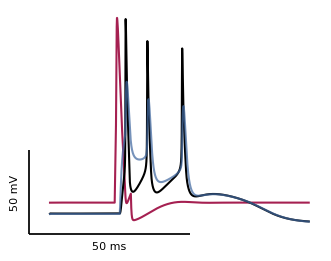

In [6]:
# single run: V traces (b) + Ca (d, black)
soma_pre, stim = drive_soma()
l5pyr = get_l5pyr(add_syn='Exp2Syn', syn_loc='basal_2')
l5pyr.syn.tau1 = 0.5
l5pyr.syn.tau2 = 5.0
nc = connect(soma_pre, l5pyr.syn, weight=0.2)

t = h.Vector().record(h._ref_t)
v_pre = h.Vector().record(soma_pre(0.5)._ref_v)
v_post_basal = h.Vector().record(l5pyr._nrn_sections['basal_2'](0.5)._ref_v)
v_post_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
ca_con = h.Vector().record(l5pyr._nrn_sections['basal_2'](0.5)._ref_cai)
h.finitialize()
h.continuerun(80)

b_t = t.as_numpy().copy()
b_vpre = v_pre.as_numpy().copy()
b_vsoma = v_post_soma.as_numpy().copy()
b_vbasal = v_post_basal.as_numpy().copy()
d_t = t.as_numpy().copy()
d_exp2_ca = ca_con.as_numpy().copy()
cleanup(stim, nc, l5pyr)

# voltage clamp sweep: NMDA-current I-V (e, black)
bamps = np.linspace(-60, 0, 5)
e_exp2_grad = np.zeros_like(bamps)
for bi, bamp in enumerate(bamps):
    soma_pre, stim = drive_soma()
    l5pyr = get_l5pyr(add_syn='Exp2Syn', syn_loc='basal_2')
    l5pyr.syn.tau1 = 0.5
    l5pyr.syn.tau2 = 5.0
    nc = connect(soma_pre, l5pyr.syn, weight=0.05)

    vclamp = h.VClamp(l5pyr._nrn_sections['basal_2'](0.5))
    vclamp.dur[0] = 10
    vclamp.amp[0] = -80
    vclamp.dur[1] = 20
    vclamp.amp[1] = bamp

    t = h.Vector().record(h._ref_t)
    nmda_curr = h.Vector().record(l5pyr.syn._ref_i)
    h.finitialize()
    h.continuerun(80)

    idx = np.where((t.as_numpy() >= 29) & (t.as_numpy() < 100))[0][0]
    e_exp2_grad[bi] = np.abs(np.min(nmda_curr.as_numpy()[idx:]))
    cleanup(stim, nc, vclamp, l5pyr)

e_bamps = bamps.copy()

fig, ax = plt.subplots(figsize=(3.2, 2.5), constrained_layout=True)
plot_b(ax)
fig.savefig(figpth / 'fig7b_exp2syn_on_l5.png', dpi=300)
fig.savefig(figpth / 'fig7b_exp2syn_on_l5.pdf', dpi=300)
plt.show()

### c, d(red), e(red) — NMDA_gao2021 on L5 `basal_2`

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod.  Aborting.
Adding synapse(s) ['NMDA_gao2021'] at ['basal_2']
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod.  Aborting.
Adding synapse(s) ['NMDA_gao2021'] at ['basal_2']
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod.  Aborting.
Adding synapse(s) ['NMDA_gao2021'] at ['basal_2']
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod.  Aborting.
Adding synapse(s) ['NMDA_gao2021'] at ['basal_2']
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod.  Aborting.
Adding synapse(s) ['NMDA_gao2021'] at ['basal_2']
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod.  Aborting.
Adding synapse(s) ['NMDA_gao20

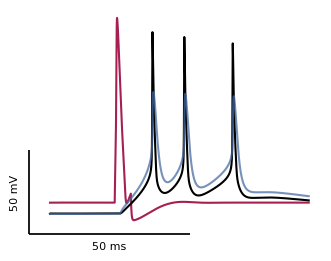

In [7]:
# single run: V traces (c) + Ca (d, red)
soma_pre, stim = drive_soma()
l5pyr = get_l5pyr(add_syn='NMDA_gao2021', syn_loc='basal_2')
nc = connect(soma_pre, l5pyr.syn, weight=0.2)

t = h.Vector().record(h._ref_t)
v_pre = h.Vector().record(soma_pre(0.5)._ref_v)
v_post_basal = h.Vector().record(l5pyr._nrn_sections['basal_2'](0.5)._ref_v)
v_post_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
ca_con = h.Vector().record(l5pyr._nrn_sections['basal_2'](0.5)._ref_cai)
h.finitialize()
h.continuerun(80)

c_t = t.as_numpy().copy()
c_vpre = v_pre.as_numpy().copy()
c_vsoma = v_post_soma.as_numpy().copy()
c_vbasal = v_post_basal.as_numpy().copy()
d_nmda_ca = ca_con.as_numpy().copy()
cleanup(stim, nc, l5pyr)

# voltage clamp sweep: NMDA-current I-V (e, red)
e_nmda_grad = np.zeros_like(bamps)
for bi, bamp in enumerate(bamps):
    soma_pre, stim = drive_soma()
    l5pyr = get_l5pyr(add_syn='NMDA_gao2021', syn_loc='basal_2')
    nc = connect(soma_pre, l5pyr.syn, weight=0.05)

    vclamp = h.VClamp(l5pyr._nrn_sections['basal_2'](0.5))
    vclamp.dur[0] = 10
    vclamp.amp[0] = -80
    vclamp.dur[1] = 20
    vclamp.amp[1] = bamp

    t = h.Vector().record(h._ref_t)
    nmda_curr = h.Vector().record(l5pyr.syn._ref_i)
    h.finitialize()
    h.continuerun(80)

    idx = np.where((t.as_numpy() >= 29) & (t.as_numpy() < 100))[0][0]
    e_nmda_grad[bi] = np.abs(np.min(nmda_curr.as_numpy()[idx:]))
    cleanup(stim, nc, vclamp, l5pyr)

fig, ax = plt.subplots(figsize=(3.2, 2.5), constrained_layout=True)
plot_c(ax)
fig.savefig(figpth / 'fig7c_nmda_on_l5.png', dpi=300)
fig.savefig(figpth / 'fig7c_nmda_on_l5.pdf', dpi=300)
plt.show()

### d — dendritic Ca²⁺ (Exp2Syn vs NMDA_gao2021)

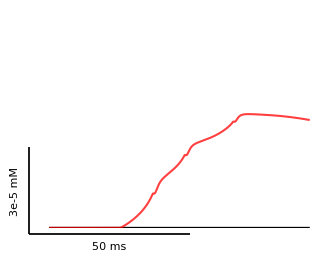

In [8]:
fig, ax = plt.subplots(figsize=(3.2, 2.5), constrained_layout=True)
plot_d(ax)
fig.savefig(figpth / 'fig7d_calcium.png', dpi=300)
fig.savefig(figpth / 'fig7d_calcium.pdf', dpi=300)
plt.show()

### e — NMDA current I–V

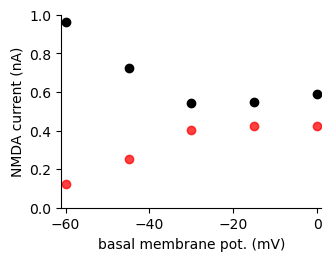

In [9]:
fig, ax = plt.subplots(figsize=(3.2, 2.5), constrained_layout=True)
plot_e(ax)
fig.savefig(figpth / 'fig7e_nmda_iv.png', dpi=300)
fig.savefig(figpth / 'fig7e_nmda_iv.pdf', dpi=300)
plt.show()

### Combined row (Fig. 7 a–e)

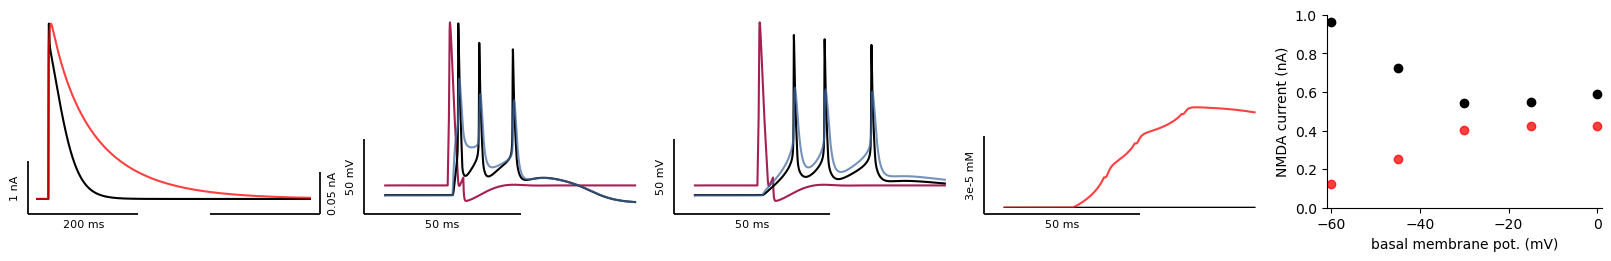

In [10]:
fig, ax = plot_row_ae()
fig.savefig(figpth / 'NMDA_vs_exp2syn.png', dpi=300)
fig.savefig(figpth / 'NMDA_vs_exp2syn.pdf', dpi=300)
plt.show()

## Fig. 7 g, h — NMDA spikes in the basal dendrites

Test membrane potential dynamics in response to excitation through NMDA only.
Uses a duecker_ET_model with all connections except the E-E NMDA connections in L5 removed.

Activates increasing number of neighboring cells while recording membrane potential in basal dendrite of center cell.

### Plotting functions (Fig. 7 g, h)

In [11]:
def plot_g(ax):
    for n_active, v in enumerate(gh_vbasal, start=1):
        ax.plot(gh_t, v, color=COL_NEIGH[n_active - 1])
    ax.set_xlabel('time (ms)')
    ax.set_ylabel('membrane potential (mV)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xlim([0, 200])
    # discrete colour bar: one band per number of active (spiking) neighbours
    cmap = mpl.colors.ListedColormap(COL_NEIGH)
    norm = mpl.colors.BoundaryNorm(np.arange(0.5, NUM_NEIGH + 1.5), cmap.N)
    cbar = ax.figure.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, orientation='horizontal', shrink=.5,
                              ticks=np.arange(1, NUM_NEIGH + 1, 4))
    cbar.minorticks_off()
    cbar.set_label('active neighbors')


def plot_h(ax):
    ax.scatter(np.arange(1, len(gh_ampl) + 1), gh_ampl, c=COL_NEIGH, marker='o')
    ax.set_xlabel('active neighbors')
    ax.set_ylabel('NMDA spike amplitude (mV)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xlim([1, NUM_NEIGH])
    ax.set_xticks(np.arange(1,NUM_NEIGH+1,4))


def plot_row_gh(fig=None):
    if fig is None:
        fig, ax = plt.subplots(1, 2, figsize=(6.5, 3.), constrained_layout=True)
    else:
        ax = fig.subplots(1, 2)
    plot_g(ax[0])
    plot_h(ax[1])
    return fig, ax

### g, h — recruiting neighbouring L5 cells

Sweeps the number of active neighbours from 1 to `NUM_NEIGH` and records the
reference cell's `basal_2` membrane potential.

running sim with 1 active neighbor(s)
MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10

running sim with 2 active neighbor(s)
MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10

running sim with 3 active neighbor(s)
MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10

running sim with 4 active neighbor(s)
MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10

running sim with 5 active neighbor(s)
MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10

running sim with 6 active neighbor(s)
MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10

running sim with 7 active neighbor(s)
MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10

running sim with 8 active n

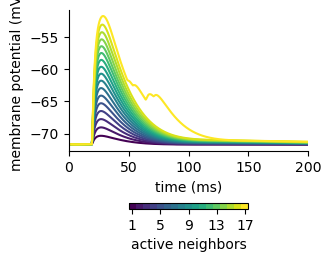

In [12]:
def l5_recurrent_net():
    """`duecker_ET_model` with only the recurrent L5->L5 proximal connection.

    All built-in connectivity is cleared and a single AMPA + NMDA E->E
    connection is put back, so nothing but recurrent excitation reaches the
    reference cell's basal dendrites.
    """
    net = duecker_ET_model()
    net.clear_connectivity()
    for receptor in ('ampa', 'nmda'):
        net.add_connection('L5_pyramidal', 'L5_pyramidal', 'proximal', receptor,
                           weight=0.00065, delay=net.delay, lamtha=6.125,
                           allow_autapses=False)
    return net


# reference cell at the centre of the grid; neighbours ordered by distance to it
net = l5_recurrent_net()
pos_to_gid = dict(zip(net.pos_dict['L5_pyramidal'],
                      net.gid_ranges['L5_pyramidal']))
ref_pos = (5.0, 5.0, 0.)
ref_gid = pos_to_gid[ref_pos]
neigh_sorted = sorted((pos for pos in pos_to_gid if pos != ref_pos),
                      key=lambda pos: math.dist(pos, ref_pos))

gh_vbasal, gh_ampl = [], []
for n_active in range(1, NUM_NEIGH + 1):
    del net
    net = l5_recurrent_net()
    stim_gids = [pos_to_gid[pos] for pos in neigh_sorted[:n_active]]
    net.add_tonic_bias(section='soma',
                       bias_name='tonic', amplitude=3, t0=15, tstop=20,
                       gid=stim_gids)
    with MPIBackend(n_procs=N_PROCS, mpi_cmd='mpiexec'):
        print(f'running sim with {n_active} active neighbor(s)')
        simulate_dipole(net, tstop=200, record_vsec='all',
                        verbose=False)
    v = np.array(net.cell_response.vsec[0][ref_gid]['basal_2'])
    gh_vbasal.append(v)
    gh_ampl.append(v.max() - v[0])

gh_t = np.array(net.cell_response.times)
gh_vbasal = np.array(gh_vbasal)
gh_ampl = np.array(gh_ampl)

fig, ax = plt.subplots(figsize=(3.2, 2.5), constrained_layout=True)
plot_g(ax)
fig.savefig(figpth / 'fig7g_nmda_spike_traces.png', dpi=300)
fig.savefig(figpth / 'fig7g_nmda_spike_traces.pdf', dpi=300)
plt.show()

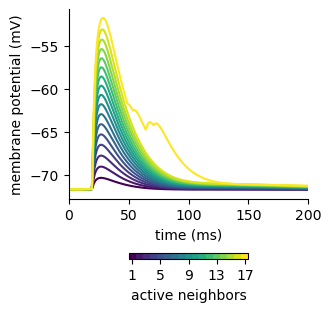

In [13]:
fig, ax = plt.subplots(figsize=(3.2, 3.), constrained_layout=True)

plot_g(ax)

### h — NMDA spike amplitude vs number of active neighbours

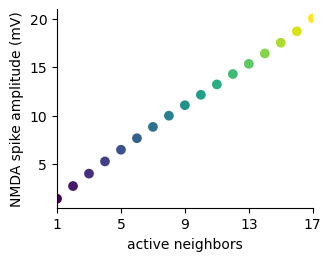

In [14]:
fig, ax = plt.subplots(figsize=(3.2, 2.5), constrained_layout=True)
plot_h(ax)
fig.savefig(figpth / 'fig7h_nmda_spike_amplitude.png', dpi=300)
fig.savefig(figpth / 'fig7h_nmda_spike_amplitude.pdf', dpi=300)
plt.show()

### Combined row (Fig. 7 g, h)

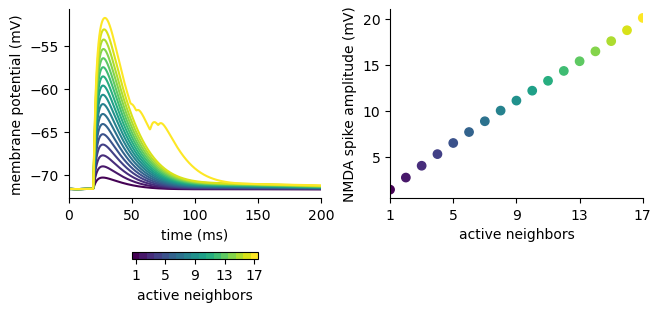

In [15]:
fig, ax = plot_row_gh()
fig.savefig(figpth / 'NMDA_spikes.png', dpi=300)
fig.savefig(figpth / 'NMDA_spikes.pdf', dpi=300)
plt.show()

## Fig. 7 i–k — NMDA vs slow GABAA


### Plotting functions (Fig. 7 i–k)

In [16]:
def plot_i(ax):
    ax.plot(ik_i_t, -1 * ik_i_nmda, color='r', alpha=0.75, label='NMDA')
    ax.plot(ik_i_t, ik_i_gabaa, color='navy', label='GABAA SOM+')
    ax.legend()
    add_scalebar(ax, x_len=100, y_len=0.1, x_label='100 ms', y_label='0.1 nA')


def plot_j(ax):
    ax.plot(ik_j_t, ik_j_vpreE, color=COL_PRE, label='pre E')
    ax.plot(ik_j_t, ik_j_vsoma, color=COL_POST_SOMA, label='L5 soma')
    ax.plot(ik_j_t, ik_j_vapcl, color=COL_POST_DEND, label='L5 apical 2')
    ax.set_ylim([-80, 50])
    add_scalebar(ax, x_len=50, y_len=50, x_label='50 ms', y_label='50 mV')


def plot_k(ax):
    ax.plot(ik_k_t, ik_k_vpreE, color=COL_PRE, label='pre E')
    ax.plot(ik_k_t, ik_k_vpreI, color='#d4a398', label='pre I')
    ax.plot(ik_k_t, ik_k_vsoma, color=COL_POST_SOMA, label='L5 soma')
    ax.plot(ik_k_t, ik_k_vapcl, color=COL_POST_DEND, label='L5 apical 2')
    ax.set_ylim([-80, 50])
    add_scalebar(ax, x_len=50, y_len=50, x_label='50 ms', y_label='50 mV')


def plot_row_ik(fig=None):
    if fig is None:
        fig, ax = plt.subplots(1, 3, figsize=(10, 2.5), constrained_layout=True)
    else:
        ax = fig.subplots(1, 3)
    plot_i(ax[0])
    plot_j(ax[1])
    plot_k(ax[2])
    return fig, ax


def plot_row_gk(fig=None):
    if fig is None:
        fig, ax = plt.subplots(1, 5, figsize=(16, 3), constrained_layout=True)
    else:
        ax = fig.subplots(1, 3)
    plot_g(ax[0])
    plot_h(ax[1])
    plot_i(ax[2])
    plot_j(ax[3])
    plot_k(ax[4])
    return fig, ax

### i — isolated NMDA vs GABA_A current

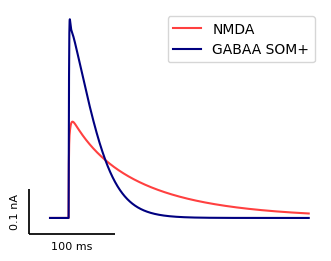

In [17]:
# NMDA_gao2021
soma_pre, stim = drive_soma()
post = make_post_basal(name='basal1')
syn = h.NMDA_gao2021(post(0.5))
nc = connect(soma_pre, syn, weight=0.1)
t = h.Vector().record(h._ref_t)
nmdacurr = h.Vector().record(syn._ref_i)
h.finitialize(-65)
h.continuerun(300)
ik_i_t = t.as_numpy().copy()
ik_i_nmda = nmdacurr.as_numpy().copy()
cleanup(stim, syn, nc, soma_pre, post)

# GABA_A (Exp2Syn, reversal -80 mV)
soma_pre, stim = drive_soma()
post = make_post_basal(name='basal2')
syn = h.Exp2Syn(post(0.5))
syn.tau1 = 1.5
syn.tau2 = 20
syn.e = -80
nc = connect(soma_pre, syn, weight=0.1)
t = h.Vector().record(h._ref_t)
gabaacurr = h.Vector().record(syn._ref_i)
h.finitialize(-65)
h.continuerun(300)
ik_i_gabaa = gabaacurr.as_numpy().copy()
cleanup(stim, syn, nc, soma_pre, post)

fig, ax = plt.subplots(figsize=(3.2, 2.5), constrained_layout=True)
plot_i(ax)
fig.savefig(figpth / 'fig7i_nmda_vs_gabaa.png', dpi=300)
fig.savefig(figpth / 'fig7i_nmda_vs_gabaa.pdf', dpi=300)
plt.show()

### j — NMDA on L5 `apical_2`

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod.  Aborting.
Adding synapse(s) ['NMDA_gao2021'] at ['apical_2']


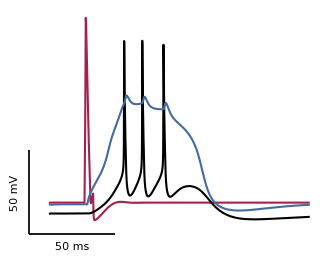

In [18]:
soma_pre, stim = drive_soma()
l5pyr = get_l5pyr(add_syn='NMDA_gao2021', syn_loc='apical_2')
nc = connect(soma_pre, l5pyr.syn, weight=0.1)

t = h.Vector().record(h._ref_t)
v_pre_E = h.Vector().record(soma_pre(0.5)._ref_v)
v_post_apcl = h.Vector().record(l5pyr._nrn_sections['apical_2'](0.5)._ref_v)
v_post_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
h.finitialize()
h.continuerun(150)

ik_j_t = t.as_numpy().copy()
ik_j_vpreE = v_pre_E.as_numpy().copy()
ik_j_vsoma = v_post_soma.as_numpy().copy()
ik_j_vapcl = v_post_apcl.as_numpy().copy()
cleanup(stim, nc, l5pyr)

fig, ax = plt.subplots(figsize=(3.2, 2.5), constrained_layout=True)
plot_j(ax)
fig.savefig(figpth / 'fig7j_nmda_on_l5_apical.png', dpi=300)
fig.savefig(figpth / 'fig7j_nmda_on_l5_apical.pdf', dpi=300)
plt.show()

### k — NMDA + GABA_A (fast) + GABA_A (SOM⁺, slow) on `apical_2`

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod.  Aborting.
Adding synapse(s) ['NMDA_gao2021', 'Exp2Syn', 'gabaa_slow'] at ['apical_2']


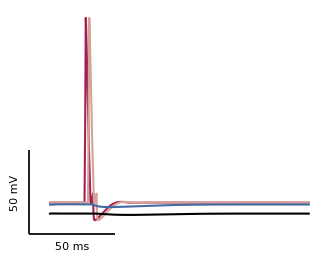

In [19]:
soma_pre_E, stim_E = drive_soma(name='soma', stim_delay=20)
soma_pre_I, stim_I = drive_soma(name='soma', stim_delay=22)

l5pyr = get_l5pyr(add_syn=['NMDA_gao2021', 'Exp2Syn', 'gabaa_slow'], syn_loc='apical_2')
nc1 = connect(soma_pre_E, l5pyr.syn[0], weight=0.0005)   # NMDA (E)
nc2 = connect(soma_pre_I, l5pyr.syn[1], weight=0.0005)   # fast GABA_A (I)
nc3 = connect(soma_pre_I, l5pyr.syn[2], weight=0.0075)   # slow GABA_A SOM+ (I)

t = h.Vector().record(h._ref_t)
v_pre_E = h.Vector().record(soma_pre_E(0.5)._ref_v)
v_pre_I = h.Vector().record(soma_pre_I(0.5)._ref_v)
v_post_apcl = h.Vector().record(l5pyr._nrn_sections['apical_2'](0.5)._ref_v)
v_post_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
h.finitialize()
h.continuerun(150)

ik_k_t = t.as_numpy().copy()
ik_k_vpreE = v_pre_E.as_numpy().copy()
ik_k_vpreI = v_pre_I.as_numpy().copy()
ik_k_vsoma = v_post_soma.as_numpy().copy()
ik_k_vapcl = v_post_apcl.as_numpy().copy()
cleanup(stim_E, stim_I, nc1, nc2, nc3, soma_pre_E, soma_pre_I, l5pyr)

fig, ax = plt.subplots(figsize=(3.2, 2.5), constrained_layout=True)
plot_k(ax)
fig.savefig(figpth / 'fig7k_ei_interplay.png', dpi=300)
fig.savefig(figpth / 'fig7k_ei_interplay.pdf', dpi=300)
plt.show()

### Combined row (Fig. 7 g–k)

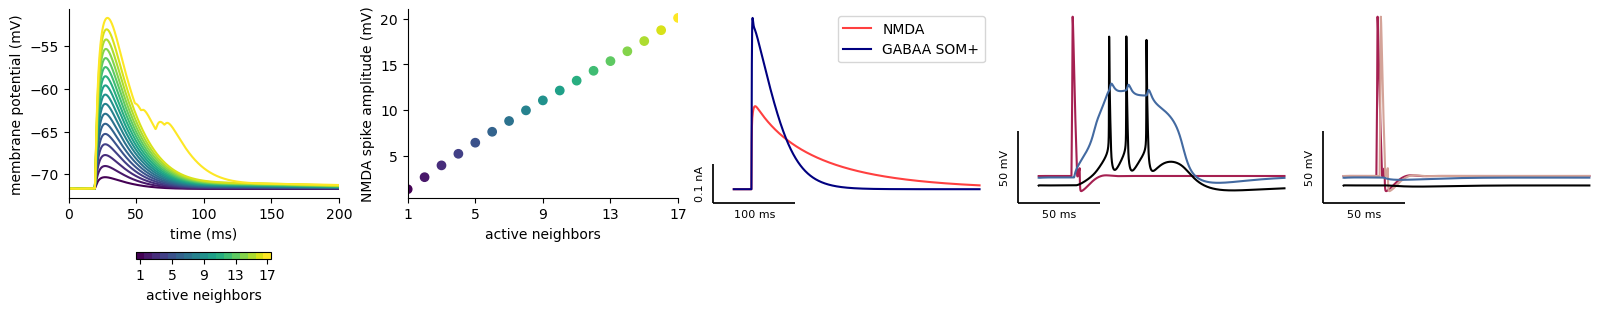

In [20]:
fig, ax = plot_row_gk()
fig.savefig(figpth / 'fig7g-k_NMDA_all.png', dpi=300)
fig.savefig(figpth / 'fig7g-k_NMDA_all.pdf', dpi=300)
plt.show()

## Fig. 7 l–n — GABA_B (old vs new)

(l) synaptic current of the old (Exp2Syn) vs new (Neymotin 2016) GABA_B model on the
apical tuft; (m, n) membrane potential when GABA_B precedes a calcium spike —
early (m) vs delayed (n) somatic drive — showing GABA_B's control of the tuft
Ca spike.

### Plotting functions (Fig. 7 l–n)

In [21]:
def plot_l(ax):
    ax.plot(ln_l_t, ln_l_old, color='gray')            # old (Exp2Syn) GABA_B
    ax.set_xlim([0, 1000])
    add_scalebar(ax, x_len=200, y_len=2, x_label='200 ms', y_label='2 nA')
    ax2 = ax.twinx()
    ax2.plot(ln_l_t, ln_l_new, color='#87C1FF')        # new (Neymotin 2016) GABA_B
    # twin (right) axis: same anchor as the left bar, mirrored horizontally
    add_scalebar(ax2, x_len=200, y_len=0.05, y_label='0.05 nA', flip_x=True,anchor=(1.03, -.03))
    return ax2


def _plot_gabab_caspike(ax, t, v_pre, v_soma, v_apical, clamp):
    ax.plot(t, v_pre, color='#c05d4d', label='pre soma')
    ax.plot(t, v_soma, color=COL_POST_SOMA, label='post soma')
    ax.plot(t, v_apical, color='#446b9f', label='post apical')
    ax.plot(t, clamp * 4 - 90, color='k')              # somatic-drive indicator
    ax.set_ylim([-95, 50])
    add_scalebar(ax, x_len=100, y_len=50, x_label='100 ms', y_label='50 mV')


def plot_m(ax):
    _plot_gabab_caspike(ax, ln_m_t, ln_m_vpre, ln_m_vsoma, ln_m_vapical, ln_m_clamp)


def plot_n(ax):
    _plot_gabab_caspike(ax, ln_n_t, ln_n_vpre, ln_n_vsoma, ln_n_vapical, ln_n_clamp)


def plot_row_ln(fig=None):
    if fig is None:
        fig, ax = plt.subplots(1, 3, figsize=(16, 2.5), constrained_layout=True)
    else:
        ax = fig.subplots(1, 3)
    plot_l(ax[0])
    plot_m(ax[1])
    plot_n(ax[2])
    return fig, ax

### l — old vs new GABA_B current

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod.  Aborting.
Adding synapse(s) ['Exp2Syn'] at ['apical_tuft']
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod.  Aborting.
Adding synapse(s) ['gabab_neymotin2016'] at ['apical_tuft']


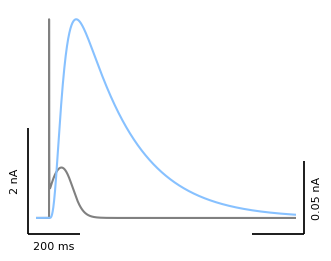

In [22]:
# old GABA_B (Exp2Syn, slow reversal -80 mV)
l5pyr = get_l5pyr(add_syn='Exp2Syn', syn_loc='apical_tuft')
l5pyr.syn.e = -80
l5pyr.syn.tau1 = 1
l5pyr.syn.tau2 = 20
soma_pre, stim = drive_soma(stim_delay=50)
nc = connect(soma_pre, l5pyr.syn, weight=.35 * 12)
t = h.Vector().record(h._ref_t)
gababcurr = h.Vector().record(l5pyr.syn._ref_i)
h.finitialize()
h.continuerun(1000)
ln_l_t = t.as_numpy().copy()
ln_l_old = gababcurr.as_numpy().copy()
cleanup(stim, nc, l5pyr)

# new GABA_B (destexhe)
l5pyr = get_l5pyr(add_syn='gabab_neymotin2016', syn_loc='apical_tuft')
soma_pre, stim = drive_soma(stim_delay=50)
nc = connect(soma_pre, l5pyr.syn, weight=.35 * 12)
t = h.Vector().record(h._ref_t)
gababcurr = h.Vector().record(l5pyr.syn._ref_i)
h.finitialize()
h.continuerun(1000)
ln_l_new = gababcurr.as_numpy().copy()
cleanup(stim, nc, l5pyr)

fig, ax = plt.subplots(figsize=(3.2, 2.5), constrained_layout=True)
plot_l(ax)
fig.savefig(figpth / 'fig7l_gabab_old_vs_new.png', dpi=300)
fig.savefig(figpth / 'fig7l_gabab_old_vs_new.pdf', dpi=300)
plt.show()

### m — GABA_B before a Ca spike (early somatic drive)

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod.  Aborting.
Adding synapse(s) ['gabab_neymotin2016'] at ['apical_tuft']


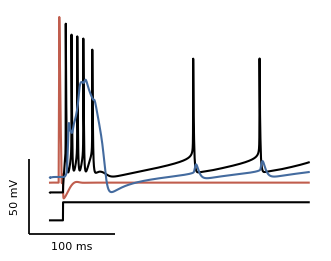

In [23]:
l5pyr = get_l5pyr(add_syn='gabab_neymotin2016', syn_loc='apical_tuft')
soma_pre, stim = drive_soma(stim_delay=10)
nc = connect(soma_pre, l5pyr.syn, weight=.4 * 10)

l5stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
l5stim.delay = 15
l5stim.dur = 300
l5stim.amp = 3
clamp_current = h.Vector().record(l5stim._ref_i)

t = h.Vector().record(h._ref_t)
v_pre = h.Vector().record(soma_pre(0.5)._ref_v)
v_post_apical = h.Vector().record(l5pyr._nrn_sections['apical_tuft'](0.5)._ref_v)
v_post_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
h.finitialize()
h.continuerun(300)

ln_m_t = t.as_numpy().copy()
ln_m_vpre = v_pre.as_numpy().copy()
ln_m_vsoma = v_post_soma.as_numpy().copy()
ln_m_vapical = v_post_apical.as_numpy().copy()
ln_m_clamp = clamp_current.as_numpy().copy()
cleanup(stim, nc, l5stim, l5pyr)

fig, ax = plt.subplots(figsize=(3.2, 2.5), constrained_layout=True)
plot_m(ax)
fig.savefig(figpth / 'fig7m_gabab_caspike_early.png', dpi=300)
fig.savefig(figpth / 'fig7m_gabab_caspike_early.pdf', dpi=300)
plt.show()

### n — GABA_B before a Ca spike (delayed somatic drive)

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-core/hnn_core/mod.  Aborting.
Adding synapse(s) ['gabab_neymotin2016'] at ['apical_tuft']


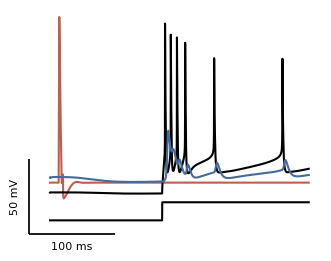

In [24]:
l5pyr = get_l5pyr(add_syn='gabab_neymotin2016', syn_loc='apical_tuft')
soma_pre, stim = drive_soma(stim_delay=10)
nc = connect(soma_pre, l5pyr.syn, weight=.4 * 10)

l5stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
l5stim.delay = 130
l5stim.dur = 300
l5stim.amp = 3
clamp_current = h.Vector().record(l5stim._ref_i)

t = h.Vector().record(h._ref_t)
v_pre = h.Vector().record(soma_pre(0.5)._ref_v)
v_post_apical = h.Vector().record(l5pyr._nrn_sections['apical_tuft'](0.5)._ref_v)
v_post_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
h.finitialize()
h.continuerun(300)

ln_n_t = t.as_numpy().copy()
ln_n_vpre = v_pre.as_numpy().copy()
ln_n_vsoma = v_post_soma.as_numpy().copy()
ln_n_vapical = v_post_apical.as_numpy().copy()
ln_n_clamp = clamp_current.as_numpy().copy()
cleanup(stim, nc, l5stim, l5pyr)

fig, ax = plt.subplots(figsize=(3.2, 2.5), constrained_layout=True)
plot_n(ax)
fig.savefig(figpth / 'fig7n_gabab_caspike_delayed.png', dpi=300)
fig.savefig(figpth / 'fig7n_gabab_caspike_delayed.pdf', dpi=300)
plt.show()

### Combined row (Fig. 7 l–n)

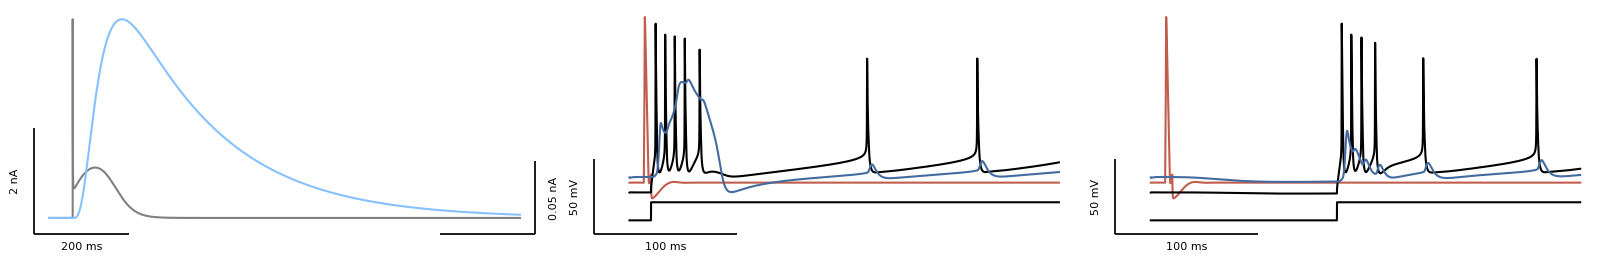

In [25]:
fig, ax = plot_row_ln()
fig.savefig(figpth / 'gabab_new_vs_old.png', dpi=300)
fig.savefig(figpth / 'gabab_new_vs_old.pdf', dpi=300)
plt.show()